# D03 — Comparaison des modèles de prévision des rendements du TLT
**QUANT LAB B07 — Économétrie de la moyenne**

L'objectif de cette étape est de comparer quatre méthodes de prévision des rendements journaliers du TLT : un modèle naïf, ARIMA, SARIMA et SARIMAX. Nous cherchons à déterminer si un modèle statistique apporte une amélioration mesurable par rapport à une prévision simple égale à zéro.

L'étude utilise les données préparées au D02. La sélection du modèle repose sur la période de validation 2023–2024 ; le test final couvre 2025 à octobre 2026. Les prévisions sont réalisées à un pas, à partir des informations disponibles avant chaque séance. La rentabilité d'une stratégie de trading n'est pas étudiée à ce stade.


In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, acf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.metrics import mean_absolute_error, mean_squared_error

CSV = Path('data/series_synchronisees.csv')
if not CSV.exists():
    CSV = Path('../data/series_synchronisees.csv')
df = pd.read_csv(CSV, parse_dates=['Date']).sort_values('Date').set_index('Date')
assert df.index.is_unique and df.index.is_monotonic_increasing
assert {'TLT_return','SPY_return','TLT_Adj_Close','SPY_Adj_Close'}.issubset(df.columns)
print('Dimensions :', df.shape, '| dates :', df.index.min().date(), 'à', df.index.max().date())
display(df.head())

Dimensions : (2220, 4) | dates : 2018-01-02 à 2026-10-30


,TLT_Adj_Close,SPY_Adj_Close,TLT_return,SPY_return
Date,,,,
2018-01-02,96.775284,235.369904,NaN,NaN
2018-01-03,97.238022,236.858551,0.004782,0.006325
2018-01-04,97.222572,237.856903,-0.000159,0.004215
2018-01-05,96.944969,239.441986,-0.002855,0.006664
2018-01-08,96.883301,239.879822,-0.000636,0.001829


## 1. Préparation des données

Nous utilisons les rendements journaliers du TLT comme variable à prévoir. La première observation sans rendement calculable est supprimée. Pour SARIMAX, nous ajoutons `SPY_lag1`, le rendement du SPY de la séance précédente, afin d'éviter d'utiliser une information du jour à prévoir.

Les données sont séparées chronologiquement : **entraînement (2018–2022)**, **validation (2023–2024)** et **test final (2025–octobre 2026)**. Cette séparation permet de comparer les modèles sur des périodes qu'ils n'ont pas utilisées pour estimer leurs paramètres.


In [2]:
data = df[['TLT_return','SPY_return']].copy()
data['SPY_lag1'] = data['SPY_return'].shift(1)
data = data.dropna()
train = data.loc['2018':'2022'].copy()
val = data.loc['2023':'2024'].copy()
test = data.loc['2025':'2026-10-30'].copy()
assert len(train)>0 and len(val)>0 and len(test)>0
assert train.index.max()<val.index.min()<test.index.min()
print('Train :',len(train),'| Validation :',len(val),'| Test :',len(test))
print('Périodes :', train.index.min().date(), train.index.max().date(), '|',val.index.min().date(),val.index.max().date(),'|',test.index.min().date(),test.index.max().date())

Train : 1257 | Validation : 502 | Test : 459
Périodes : 2018-01-04 2022-12-30 | 2023-01-03 2024-12-31 | 2025-01-02 2026-10-30


## 2. Analyse descriptive

Le graphique distingue l'évolution du prix ajusté du TLT et celle de ses rendements journaliers. Les rendements fluctuent autour de zéro, avec des mouvements parfois importants. Sur les 2 218 observations retenues, leur moyenne est proche de zéro (environ −0,00003) et leur écart-type est d'environ 0,00964, soit 0,964 % par séance.

Nous modélisons les rendements plutôt que les prix, car notre objectif est de prévoir la variation quotidienne de l'actif.


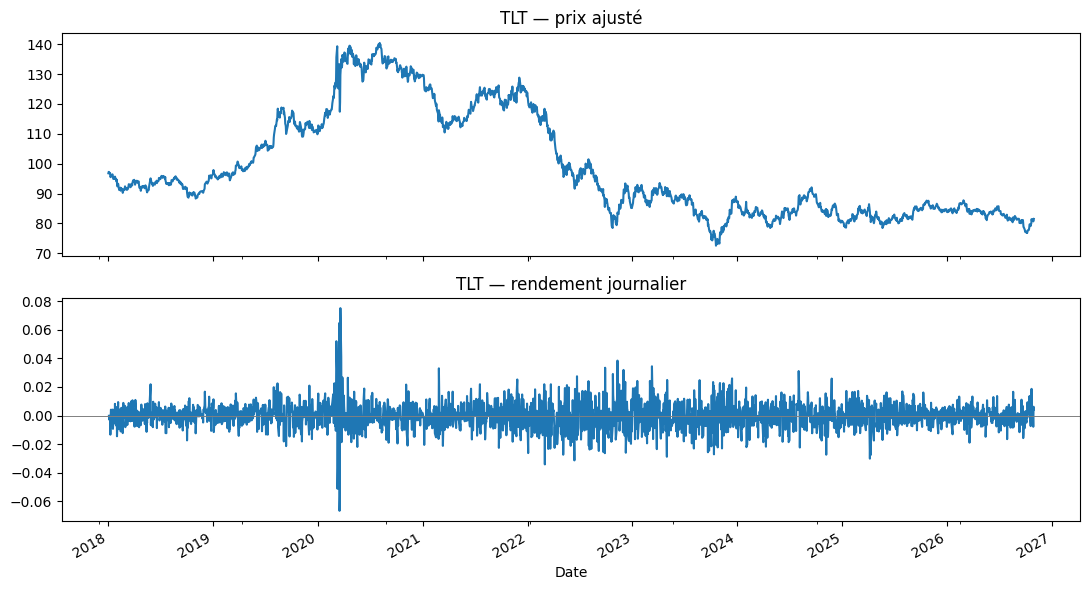

       TLT_return  SPY_return
count  2218.00000  2218.00000
mean     -0.00003     0.00059
std       0.00964     0.01193
min      -0.06668    -0.10942
25%      -0.00577    -0.00431
50%       0.00009     0.00080
75%       0.00558     0.00644
max       0.07519     0.10502


In [3]:
fig, axes = plt.subplots(2,1,figsize=(11,6),sharex=True)
df['TLT_Adj_Close'].plot(ax=axes[0],title='TLT — prix ajusté')
data['TLT_return'].plot(ax=axes[1],title='TLT — rendement journalier')
axes[1].axhline(0,color='gray',lw=.7)
plt.tight_layout();plt.show()
print(data[['TLT_return','SPY_return']].describe().round(5))

## 3. Vérification de la stationnarité

Le test ADF est appliqué aux rendements TLT de la période d'entraînement. Il permet de tester l'hypothèse d'une racine unitaire.

La statistique obtenue est **−10,4689** et la p-value est d'environ **1,30 × 10⁻¹⁸**, bien inférieure à 5 %. Nous rejetons donc l'hypothèse de racine unitaire. Ce résultat soutient le choix d'une modélisation des rendements sans différenciation supplémentaire (`d=0`). Il ne garantit pas que toutes les propriétés statistiques de la série restent constantes.


In [4]:
adf = adfuller(train['TLT_return'],autolag='AIC')
print(f'ADF statistique : {adf[0]:.4f} | p-value : {adf[1]:.5g}')
print('Rejet de la racine unitaire au seuil 5 %' if adf[1]<0.05 else 'Racine unitaire non rejetée au seuil 5 %')

ADF statistique : -10.4689 | p-value : 1.2998e-18
Rejet de la racine unitaire au seuil 5 %


C:\Users\USER\AppData\Local\Temp\ipykernel_21452\1578037245.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf = adfuller(train['TLT_return'],autolag='AIC')


## 4. Modèles comparés et méthode de prévision

- **Naïf :** prévoit un rendement nul ; il sert de référence.
- **ARIMA(1,0,1) :** utilise les relations entre rendements passés et erreurs passées.
- **SARIMA(1,0,0)(1,0,0,5) :** examine une éventuelle dynamique sur cinq séances boursières.
- **SARIMAX(1,0,0) :** ajoute le rendement du SPY de la veille comme variable explicative.

Les ordres retenus sont volontairement simples et permettent une première comparaison. Les prévisions sont effectuées séance par séance : après chaque prévision, la valeur réellement observée est intégrée pour préparer la séance suivante, **sans réestimer les paramètres**. Les données futures ne sont pas utilisées pour prévoir le passé.

La comparaison principale repose sur la **RMSE** (erreur quadratique moyenne racine), complétée par la **MAE** (erreur absolue moyenne). Plus ces valeurs sont faibles, meilleure est la précision numérique. Le pourcentage de direction correcte est donné à titre indicatif ; pour le modèle naïf qui prévoit zéro, cette mesure n'est pas directement comparable.


In [5]:
SPECS = {
    'ARIMA': {'order':(1,0,1)},
    'SARIMA': {'order':(1,0,0),'seasonal_order':(1,0,0,5)},
    'SARIMAX': {'order':(1,0,0),'exog':True},
}

def fit_model(name, history):
    y = history['TLT_return'].reset_index(drop=True)
    if name == 'ARIMA':
        return ARIMA(y, order=(1,0,1), trend='c').fit()
    if name == 'SARIMA':
        return SARIMAX(y, order=(1,0,0), seasonal_order=(1,0,0,5), trend='c', enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=100)
    if name == 'SARIMAX':
        return SARIMAX(y, exog=history[['SPY_lag1']].reset_index(drop=True), order=(1,0,0), trend='c', enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=100)
    raise ValueError(name)

def predict_one_step(name, fitted, future):
    # La date t utilise l'état actualisé jusqu'à t-1 et SPY(t-1) seulement.
    preds=[]
    state=fitted
    for date, row in future.iterrows():
        next_idx = state.nobs  # index numérique suivant, sans réinitialisation à 0
        x = pd.DataFrame({'SPY_lag1':[row['SPY_lag1']]}, index=[next_idx]) if name=='SARIMAX' else None
        p=state.forecast(steps=1,exog=x) if x is not None else state.forecast(steps=1)
        preds.append(float(p.iloc[0]))
        observed=pd.Series([row['TLT_return']],index=[next_idx],name='TLT_return')
        state=state.append(observed,exog=x,refit=False) if x is not None else state.append(observed,refit=False)
    return pd.Series(preds,index=future.index,name=name)

def metrics(actual, predicted):
    return {'MAE':mean_absolute_error(actual,predicted),
            'RMSE':np.sqrt(mean_squared_error(actual,predicted)),
            'Direction (%)':100*np.mean(np.sign(actual)==np.sign(predicted))}


## 5. Résultats sur la période de validation (2023–2024)

Les quatre modèles sont évalués sur les mêmes 502 séances. Le choix est effectué à partir de la RMSE, sans consulter les résultats du test final.

**ARIMA arrive en première position**, avec une RMSE de **0,010317** et une MAE de **0,008246**. Le modèle naïf suit de près (RMSE **0,010338**), puis SARIMAX (**0,010339**) et SARIMA (**0,010428**).

L'amélioration d'ARIMA par rapport au naïf est donc **réelle dans cet échantillon, mais très faible** : environ **0,20 % de réduction de RMSE**. SARIMAX obtient une meilleure proportion de directions correctes (environ 51,99 %), mais pas la meilleure précision selon la RMSE. Nous retenons ARIMA conformément au critère fixé.


In [6]:
validation_predictions={'Naif':pd.Series(0.0,index=val.index)}
validation_models={}
for name in SPECS:
    print('Validation :',name)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        fitted=fit_model(name,train)
        validation_predictions[name]=predict_one_step(name,fitted,val)
        validation_models[name]=fitted
val_scores=pd.DataFrame({name:metrics(val['TLT_return'],p) for name,p in validation_predictions.items()}).T.sort_values('RMSE')
display(val_scores.round(6))
best_name=val_scores.index[0]
print('Meilleur modèle selon RMSE sur validation :',best_name)


Validation : ARIMA
Validation : SARIMA
Validation : SARIMAX


,MAE,RMSE,Direction (%)
ARIMA,0.008246,0.010317,48.804781
Naif,0.008267,0.010338,0.398406
SARIMAX,0.008270,0.010339,51.992032
SARIMA,0.008359,0.010428,46.613546


Meilleur modèle selon RMSE sur validation : ARIMA


## 6. Diagnostics et limites des modèles

Le test de Ljung-Box, calculé ici sur les résidus des modèles ajustés à l'entraînement (retard 10), donne des p-values affichées à **0,0** pour ARIMA, SARIMA et SARIMAX. Ces valeurs sont arrondies à l'affichage : elles ne signifient pas que la probabilité est exactement nulle.

Au seuil de 5 %, les résultats indiquent qu'il subsiste une autocorrélation des résidus. Les modèles ne capturent donc pas complètement la dépendance temporelle des données. Les critères AIC affichés apportent une information supplémentaire sur l'ajustement, mais la sélection finale repose sur la RMSE de validation.

Le graphique ci-dessous permet de comparer visuellement les prévisions produites sur la période de validation.


ARIMA | AIC : -7966.22 | Ljung-Box p-value (lag 10) : 0.0
SARIMA | AIC : -7930.48 | Ljung-Box p-value (lag 10) : 0.0
SARIMAX | AIC : -7963.53 | Ljung-Box p-value (lag 10) : 0.0


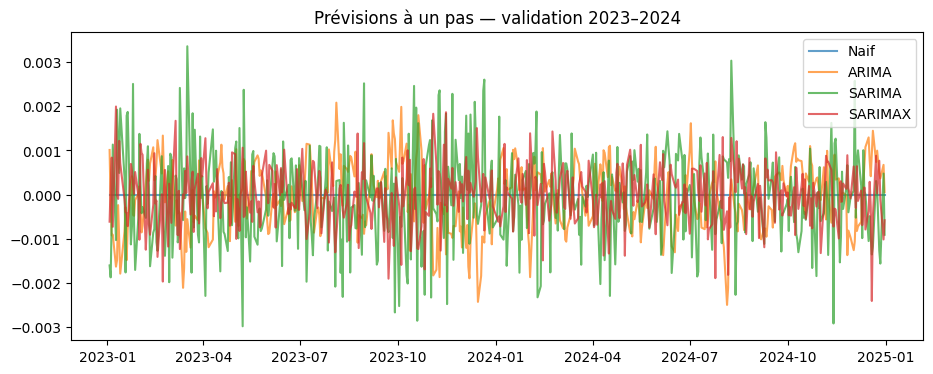

In [7]:
for name, fitted in validation_models.items():
    resid=pd.Series(fitted.resid).dropna()
    lb=acorr_ljungbox(resid,lags=[10],return_df=True)
    print(name,'| AIC :',round(fitted.aic,2),'| Ljung-Box p-value (lag 10) :',round(float(lb['lb_pvalue'].iloc[0]),5))
fig,ax=plt.subplots(figsize=(11,4))
for name in ['Naif','ARIMA','SARIMA','SARIMAX']:
    ax.plot(val.index,validation_predictions[name].values,label=name,alpha=.7)
ax.set_title('Prévisions à un pas — validation 2023–2024');ax.legend();plt.show()

## 7. Évaluation finale sur la période de test (2025–octobre 2026)

Après sa sélection sur la validation, ARIMA est réestimé sur l'ensemble **2018–2024**, puis évalué sur **459 séances de test**. Le modèle naïf est conservé comme référence.

ARIMA obtient une **RMSE de 0,006946** et une **MAE de 0,005415**, contre **0,006953** et **0,005422** pour le naïf. Le taux de direction correcte d'ARIMA est d'environ **51,85 %**. La précision numérique est donc légèrement meilleure que celle de la référence, mais le gain reste très limité (environ **0,10 % de RMSE**).

Ces résultats confirment un petit avantage statistique d'ARIMA sur cette période, sans démontrer une amélioration robuste ni une rentabilité en trading.


In [9]:
trainval=pd.concat([train,val])
naive_test=pd.Series(0.0,index=test.index,name='Naif')
if best_name=='Naif':
    best_test=naive_test.copy()
else:
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        final_fit=fit_model(best_name,trainval)
        best_test=predict_one_step(best_name,final_fit,test)
test_scores=pd.DataFrame({'Naif':metrics(test['TLT_return'],naive_test),best_name:metrics(test['TLT_return'],best_test)}).T
display(test_scores.round(6))
result=pd.DataFrame({'TLT_return_reel':test['TLT_return'],'prediction':best_test})
result.index.name='Date'
from pathlib import Path

# Enregistrer les résultats à la racine du projet
OUT = Path("../reports/D03") if Path.cwd().name == "notebooks" else Path("reports/D03")

OUT.mkdir(parents=True, exist_ok=True)

result.to_csv(OUT / "previsions_test.csv")
val_scores.to_csv(OUT / "comparaison_validation.csv")
test_scores.to_csv(OUT / "comparaison_test.csv")

print("Fichiers enregistrés dans :", OUT.resolve())

,MAE,RMSE,Direction (%)
Naif,0.005422,0.006953,0.217865
ARIMA,0.005415,0.006946,51.851852


Fichiers enregistrés dans : C:\Users\USER\Downloads\QUANT_LAB_B07_D03_preparation\reports\D03


## 8. Conclusion générale

Cette comparaison montre que les rendements journaliers du TLT peuvent être modélisés avec des méthodes classiques de séries temporelles, mais qu'ils restent difficiles à prévoir avec précision.

Le test ADF soutient l'utilisation des rendements sans différenciation supplémentaire. Parmi les modèles évalués, **ARIMA(1,0,1)** obtient la plus faible RMSE en validation et conserve un léger avantage sur le modèle naïf lors du test final. Cependant, les différences sont très petites et les diagnostics de Ljung-Box montrent que les résidus ne sont pas entièrement dépourvus d'autocorrélation.

**Nous retenons donc ARIMA comme meilleur modèle de ce premier comparatif, avec prudence.** Les résultats ne permettent pas d'affirmer qu'il sera profitable en trading : il faudra encore examiner les signaux de décision, les coûts de transaction, le risque et la performance d'une stratégie hors échantillon.

**Limites de l'étude :** ordres des modèles fixés à l'avance, hypothèse d'une structure sur cinq séances pour SARIMA, choix d'une seule variable externe retardée pour SARIMAX et absence de test de rentabilité à ce stade.
